In [3]:
import os
os.chdir(r"E:\AI\Car Purchase Prediction Model\car-recommender")

import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import shap
import joblib
from pathlib import Path

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.figsize": (11, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Load model and test data
model = joblib.load("models/lgbm_tuned.pkl")

X_test  = pl.read_parquet("data/processed/X_test.parquet")
y_test  = pl.read_parquet("data/processed/y_test.parquet")["log_price"].to_numpy()

# Load the original cleaned test set (has make, model, price columns)
test_raw = pl.read_parquet("data/processed/test.parquet")

feat_names = X_test.columns
X_test_np  = X_test.to_numpy()

# Predict
y_pred = model.predict(X_test_np)

# Error in dollars
true_dollars = np.exp(y_test)
pred_dollars = np.exp(y_pred)
error_dollars = pred_dollars - true_dollars      # signed error
abs_error     = np.abs(error_dollars)
pct_error     = np.abs(error_dollars / true_dollars) * 100

print(f"Test MAE:  ${np.mean(abs_error):,.0f}")
print(f"Test MAPE: {np.mean(pct_error):.2f}%")
print(f"Test R²:   {1 - np.sum((y_test-y_pred)**2)/np.sum((y_test-y_test.mean())**2):.4f}")

Test MAE:  $1,635
Test MAPE: 6.25%
Test R²:   0.9744


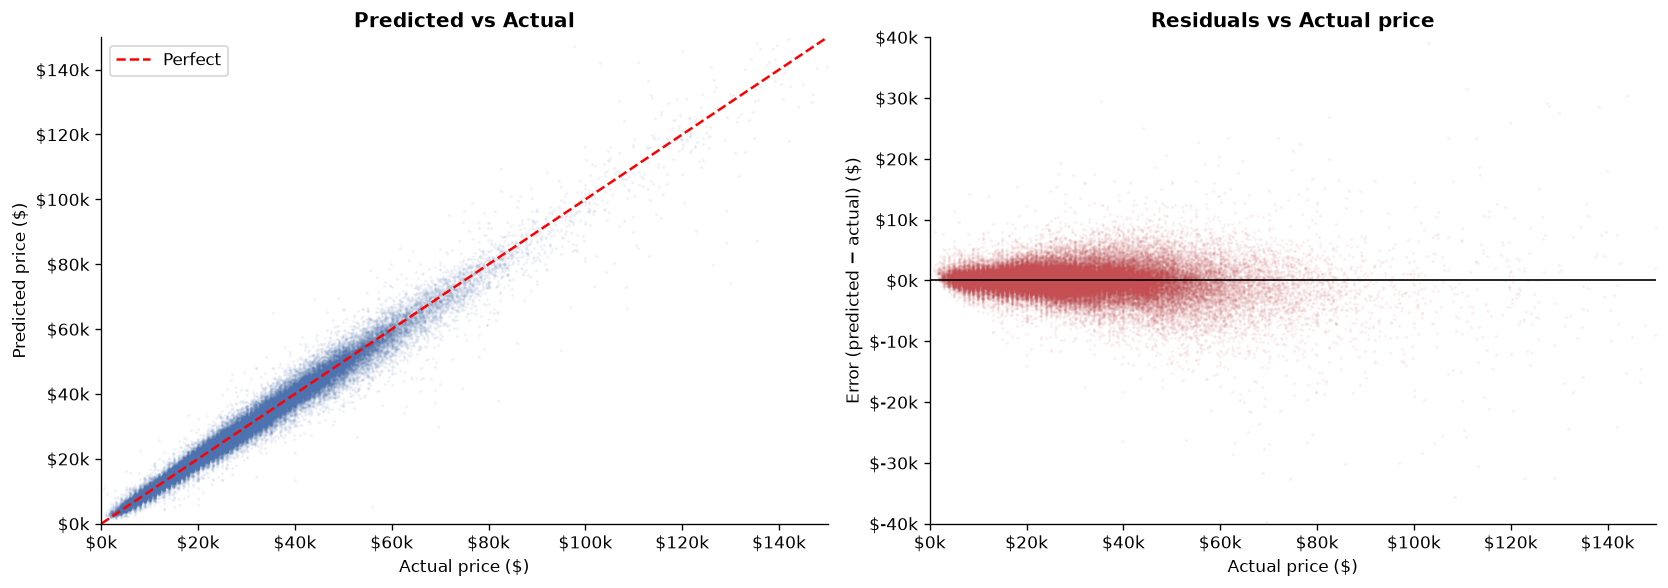

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Predicted vs Actual ───────────────────────────────────────────────────────
axes[0].scatter(true_dollars, pred_dollars,
                alpha=0.05, s=1, color="#4C72B0")
axes[0].plot([0, 150_000], [0, 150_000],
             color="red", linewidth=1.5, linestyle="--", label="Perfect")
axes[0].set_xlim(0, 150_000)
axes[0].set_ylim(0, 150_000)
axes[0].set_xlabel("Actual price ($)")
axes[0].set_ylabel("Predicted price ($)")
axes[0].set_title("Predicted vs Actual", fontweight="bold")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x/1000:.0f}k"))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x/1000:.0f}k"))
axes[0].legend()

# ── Residuals vs Actual ───────────────────────────────────────────────────────
axes[1].scatter(true_dollars, error_dollars,
                alpha=0.05, s=1, color="#C44E52")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlim(0, 150_000)
axes[1].set_ylim(-40_000, 40_000)
axes[1].set_xlabel("Actual price ($)")
axes[1].set_ylabel("Error (predicted − actual) ($)")
axes[1].set_title("Residuals vs Actual price", fontweight="bold")
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x/1000:.0f}k"))
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"${x/1000:.0f}k"))

plt.tight_layout()
plt.savefig("docs/plot_residuals.png", bbox_inches="tight")
plt.show()

MAPE by price segment:
                   MAPE      n
price_bucket                  
<$10k         15.454500   5452
$10-20k        6.875318  16562
$20-35k        5.018585  29391
$35-60k        5.057183  18525
$60k+          5.564437   3243

MAPE by salvage status:
              MAPE      n
salvage                  
False     6.236807  73020
True     11.763300    231

MAPE by car age:
                 MAPE      n
age_bucket                  
0-2 yrs      5.002660  45485
3-5 yrs      6.411271  13667
6-10 yrs     9.801423   6541
11-15 yrs   15.361798   2462
15+ yrs     28.861581    828


C:\Users\criya\AppData\Local\Temp\ipykernel_13472\1301102192.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(seg.index.astype(str), rotation=20, ha="right")
C:\Users\criya\AppData\Local\Temp\ipykernel_13472\1301102192.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(seg.index.astype(str), rotation=20, ha="right")
C:\Users\criya\AppData\Local\Temp\ipykernel_13472\1301102192.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(seg.index.astype(str), rotation=20, ha="right")


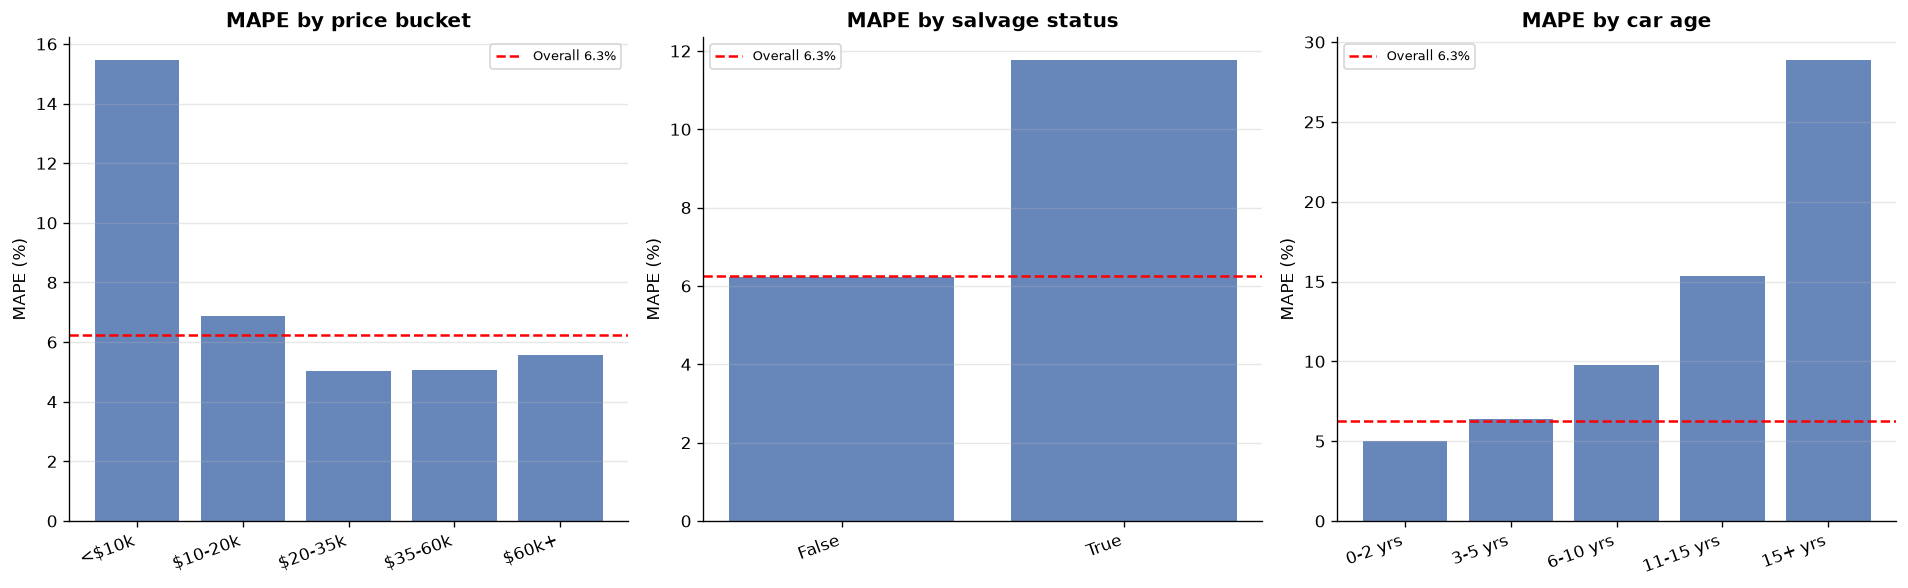

In [5]:
# Build analysis dataframe
analysis = test_raw.select([
    "make_name", "model_name", "year", "price",
    "is_new", "salvage", "mileage", "body_type"
]).to_pandas()

analysis["true_price"]  = true_dollars
analysis["pred_price"]  = pred_dollars
analysis["abs_error"]   = abs_error
analysis["pct_error"]   = pct_error
analysis["error"]       = error_dollars

# ── Segment 1: by price bucket ────────────────────────────────────────────────
analysis["price_bucket"] = pd.cut(
    analysis["true_price"],
    bins=[0, 10_000, 20_000, 35_000, 60_000, 150_000],
    labels=["<$10k", "$10-20k", "$20-35k", "$35-60k", "$60k+"]
)

seg_price = (analysis.groupby("price_bucket", observed=True)["pct_error"]
             .agg(["mean", "count"])
             .rename(columns={"mean": "MAPE", "count": "n"}))

# ── Segment 2: salvage vs clean ───────────────────────────────────────────────
seg_salvage = (analysis.groupby("salvage")["pct_error"]
               .agg(["mean", "count"])
               .rename(columns={"mean": "MAPE", "count": "n"}))

# ── Segment 3: by car age ─────────────────────────────────────────────────────
analysis["age"] = 2020 - analysis["year"]   # dataset is 2019-2020
analysis["age_bucket"] = pd.cut(
    analysis["age"],
    bins=[-1, 2, 5, 10, 15, 100],
    labels=["0-2 yrs", "3-5 yrs", "6-10 yrs", "11-15 yrs", "15+ yrs"]
)
seg_age = (analysis.groupby("age_bucket", observed=True)["pct_error"]
           .agg(["mean", "count"])
           .rename(columns={"mean": "MAPE", "count": "n"}))

print("MAPE by price segment:")
print(seg_price.to_string())
print("\nMAPE by salvage status:")
print(seg_salvage.to_string())
print("\nMAPE by car age:")
print(seg_age.to_string())

# Plot
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, seg, title in [
    (axes[0], seg_price,   "MAPE by price bucket"),
    (axes[1], seg_salvage, "MAPE by salvage status"),
    (axes[2], seg_age,     "MAPE by car age"),
]:
    bars = ax.bar(seg.index.astype(str), seg["MAPE"],
                  color="#4C72B0", alpha=0.85)
    ax.axhline(np.mean(pct_error), color="red",
               linestyle="--", label=f"Overall {np.mean(pct_error):.1f}%")
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("MAPE (%)")
    ax.set_xticklabels(seg.index.astype(str), rotation=20, ha="right")
    ax.legend(fontsize=8)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("docs/plot_error_segments.png", bbox_inches="tight")
plt.show()

In [6]:
# Top 20 worst predictions by absolute error
worst = (analysis.nlargest(20, "abs_error")
         [["make_name", "model_name", "year", "true_price",
           "pred_price", "abs_error", "pct_error", "salvage"]]
         .reset_index(drop=True))

worst["true_price"]  = worst["true_price"].map("${:,.0f}".format)
worst["pred_price"]  = worst["pred_price"].map("${:,.0f}".format)
worst["abs_error"]   = worst["abs_error"].map("${:,.0f}".format)
worst["pct_error"]   = worst["pct_error"].map("{:.1f}%".format)

print("Top 20 worst predictions:")
print(worst.to_string())

Top 20 worst predictions:
        make_name              model_name  year true_price pred_price abs_error pct_error  salvage
0         Porsche                     911  2018   $285,000   $159,734  $125,266     44.0%    False
1         McLaren                    720S  2018   $250,000   $131,477  $118,523     47.4%    False
2         Porsche                  Taycan  2020   $209,950    $94,395  $115,555     55.0%    False
3     Rolls-Royce  Phantom Drophead Coupe  2011   $209,990   $145,263   $64,727     30.8%    False
4         Ferrari              458 Italia  2014   $189,995   $128,328   $61,667     32.5%    False
5           Dodge                   Viper  2017   $199,000   $138,190   $60,810     30.6%    False
6   Mercedes-Benz             SLR McLaren  2008   $299,999   $243,909   $56,090     18.7%    False
7         Ferrari            California T  2016   $129,900    $74,115   $55,785     42.9%    False
8    Freightliner                Sprinter  2008    $55,990     $5,242   $50,748    

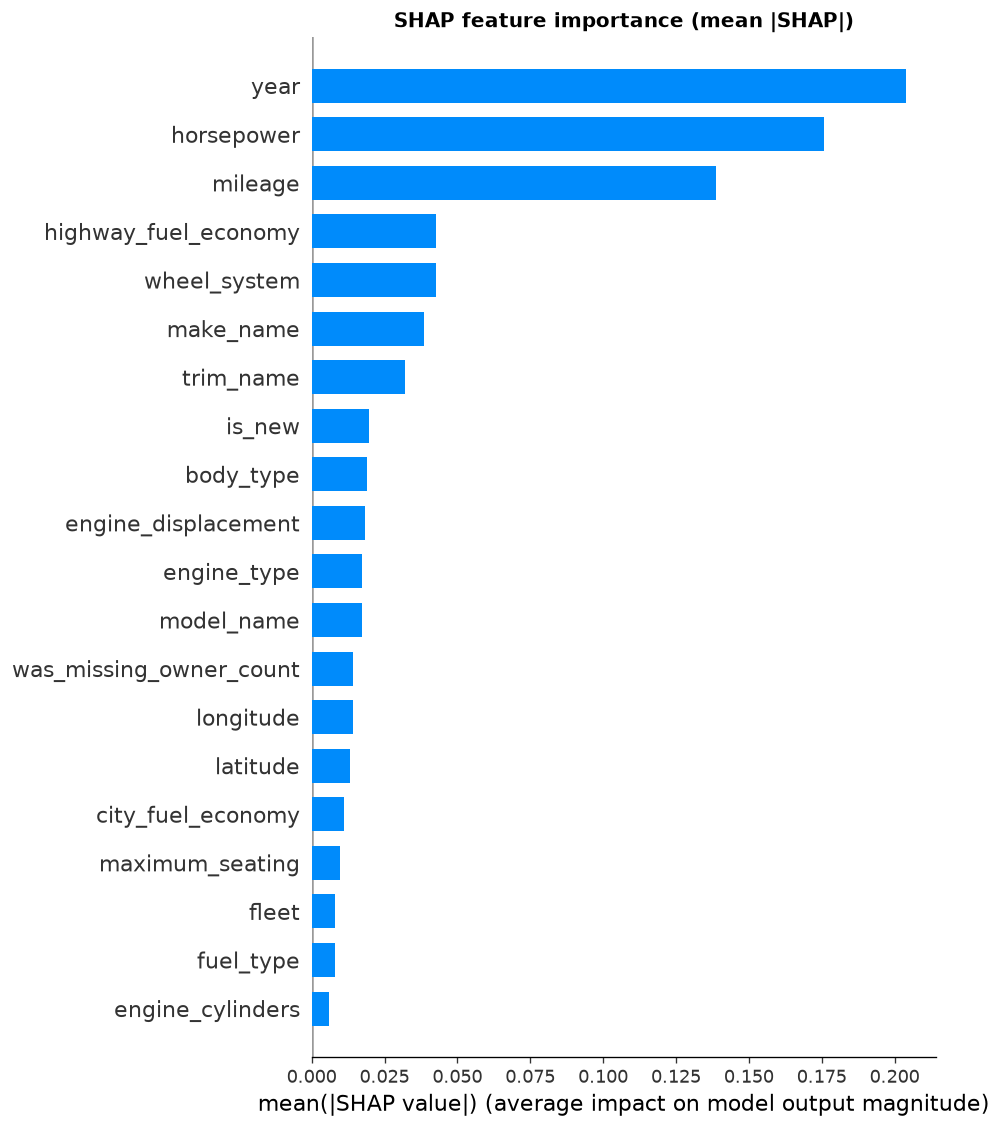

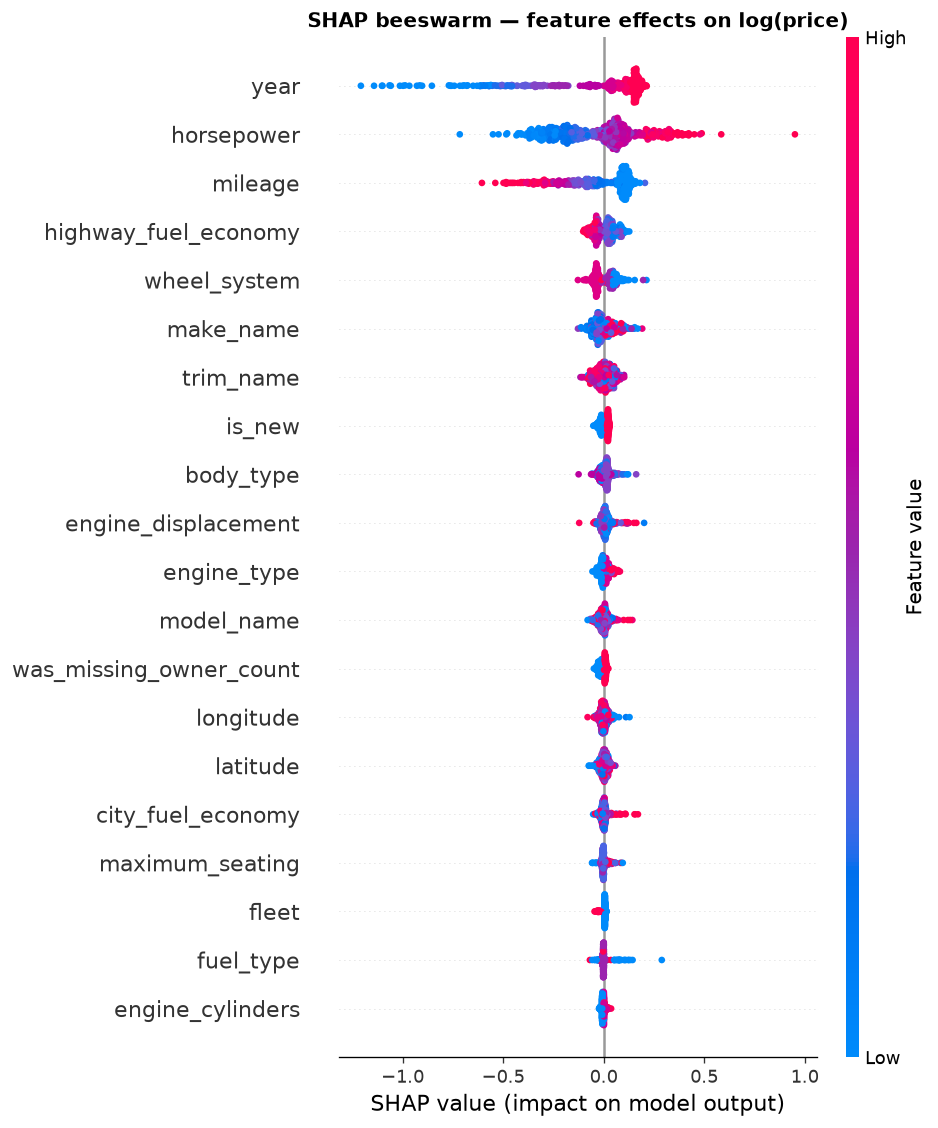

In [7]:
# SHAP explains WHY the model made each prediction
explainer  = shap.TreeExplainer(model)
# Use 500 test rows — full set is slow
X_shap = X_test_np[:500]
shap_values = explainer.shap_values(X_shap)

# ── Global feature importance (SHAP) ─────────────────────────────────────────
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_shap,
                  feature_names=feat_names,
                  plot_type="bar",
                  show=False)
plt.title("SHAP feature importance (mean |SHAP|)", fontweight="bold")
plt.tight_layout()
plt.savefig("docs/plot_shap_importance.png", bbox_inches="tight")
plt.show()

# ── SHAP beeswarm (shows direction too) ───────────────────────────────────────
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_shap,
                  feature_names=feat_names,
                  show=False)
plt.title("SHAP beeswarm — feature effects on log(price)", fontweight="bold")
plt.tight_layout()
plt.savefig("docs/plot_shap_beeswarm.png", bbox_inches="tight")
plt.show()


Explaining prediction for test car #100:
  Make/Model/Year: Audi A3 2020
  True price:  $34,725
  Predicted:   $35,779
  Error:       $1,054


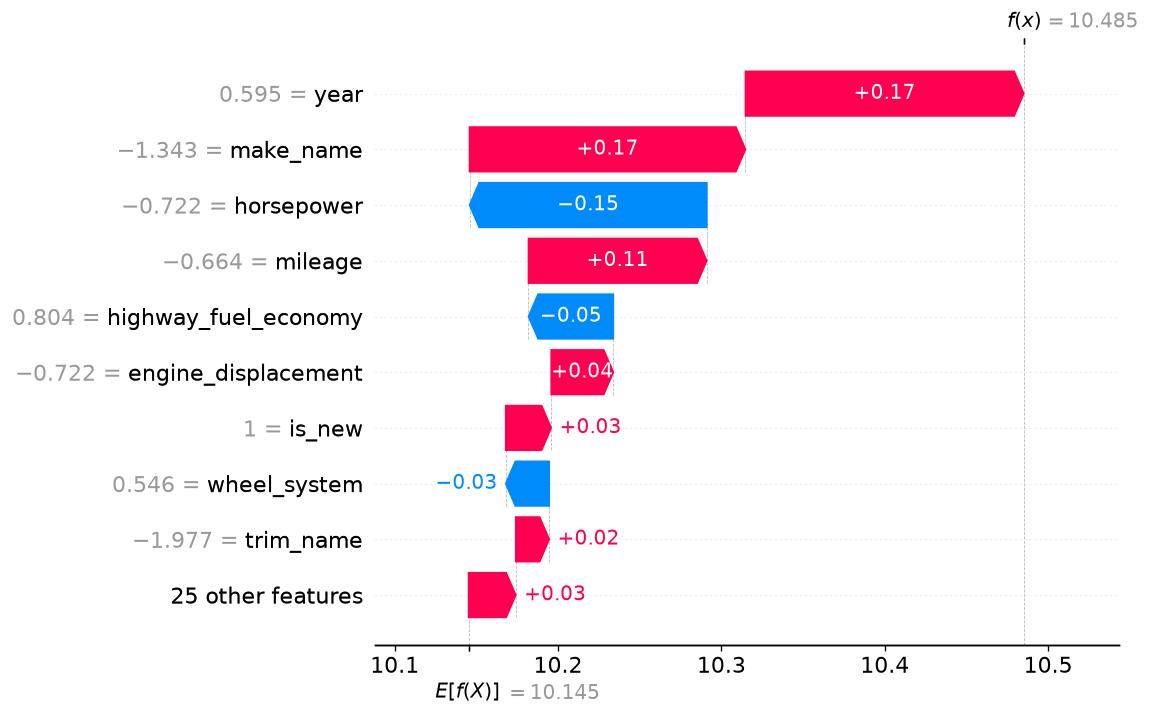

In [8]:
# Explain one specific prediction — most interesting: a car with large error
worst_idx = analysis["abs_error"].apply(lambda x: float(x.replace('$','').replace(',',''))).idxmax() \
    if isinstance(analysis["abs_error"].iloc[0], str) else analysis["abs_error"].idxmax()

# Pick a clean example instead — the 100th test car
i = 100
print(f"\nExplaining prediction for test car #{i}:")
print(f"  Make/Model/Year: {analysis.iloc[i]['make_name']} "
      f"{analysis.iloc[i]['model_name']} {analysis.iloc[i]['year']}")
print(f"  True price:  ${np.exp(y_test[i]):,.0f}")
print(f"  Predicted:   ${np.exp(y_pred[i]):,.0f}")
print(f"  Error:       ${abs(np.exp(y_pred[i]) - np.exp(y_test[i])):,.0f}")

shap.waterfall_plot(
    shap.Explanation(
        values=shap_values[i],
        base_values=explainer.expected_value,
        data=X_shap[i],
        feature_names=feat_names
    )
)